# 05 · Difficulty models: training, evaluation & explainability
| Model | Idea |
|---|---|
| TF-IDF + LogReg / Ridge | strong linear baseline |
| LightGBM (linguistic features) | interpretable features only |
| LightGBM (linguistic + stacked TF-IDF) | gradient boosting, explained with SHAP |
| BiLSTM + attention | deep learning from scratch with our Word2Vec embeddings |
| DistilBERT multi-task | fine-tuned transformer: level head + score head |
| **Ensemble** | weighted combination, tuned on validation |

Metrics: accuracy, macro-F1, quadratic weighted kappa (ordinal agreement) for the **level**;
MAE, RMSE, Spearman for the **0-100 score**.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)
REPORTS = ROOT / 'reports'; FIG = REPORTS / 'figures'
def show(name): display(Image(filename=str(FIG / name)))
def rj(name): return json.loads((REPORTS / name).read_text())

In [2]:
mc = pd.read_csv(REPORTS/'model_comparison.csv'); mc.round(4)

,model,accuracy,macro_f1,qwk,mae,rmse,spearman,band_accuracy
0,LightGBM (linguistic features only),0.7282,0.7310,0.7388,9.3564,12.4473,0.8240,0.6722
1,BiLSTM + attention (from scratch),0.7387,0.7414,0.7678,8.9093,11.7321,0.8326,0.6952
2,TF-IDF + LogReg/Ridge (baseline),0.7600,0.7636,0.7866,9.1881,11.8205,0.8332,0.6622
3,LightGBM (linguistic + stacked TF-IDF),0.7813,0.7843,0.8116,7.3906,10.1488,0.8738,0.7480
4,DistilBERT (multi-task),0.7913,0.7922,0.8264,6.9396,9.9761,0.8842,0.7918
5,Ensemble (final),0.8013,0.8021,0.8345,6.6129,9.6403,0.8890,0.8013


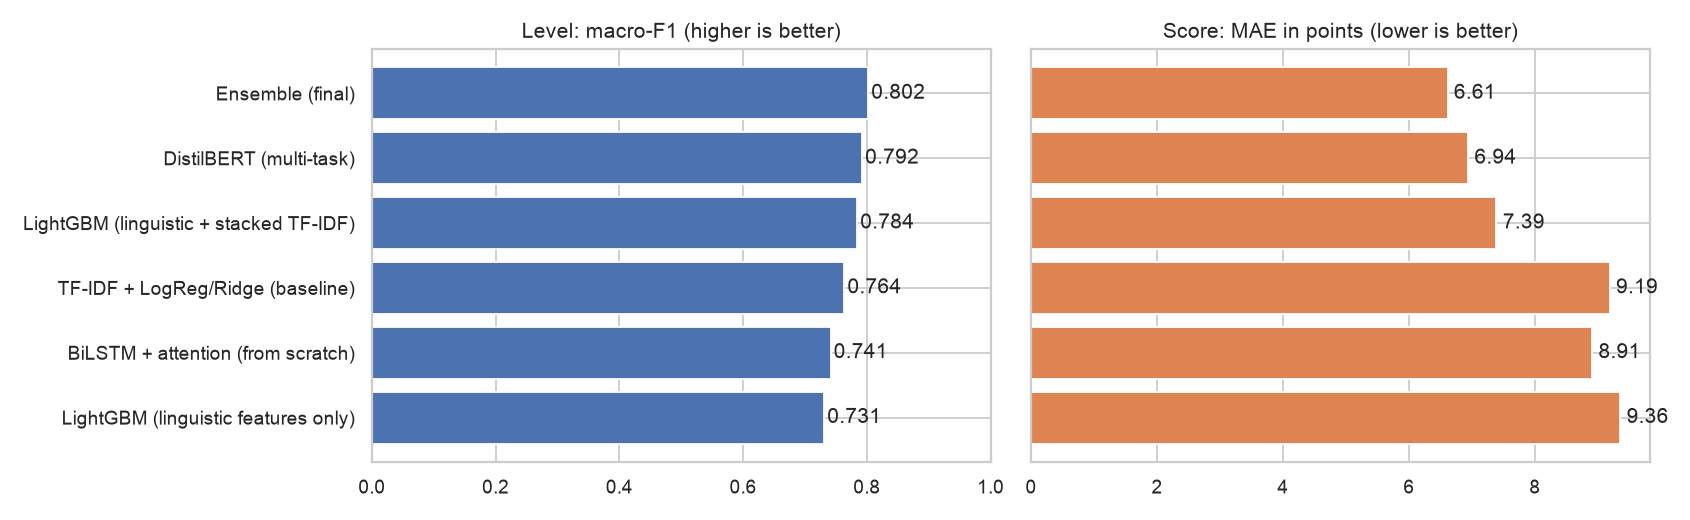

In [3]:
show('model_comparison.png')

In [4]:
h = json.loads((ROOT/'models_store/distilbert_difficulty/history.json').read_text()); pd.DataFrame(h).round(4)

,epoch,train_loss,accuracy,macro_f1,qwk,mae,rmse,spearman,band_accuracy
0,1,0.3878,0.8179,0.8152,0.853,6.5843,9.4132,0.9061,0.8166


Ensemble configuration: {'weights': {'gbm': 0.4, 'bert': 0.6000000000000001, 'bilstm': 0.0}, 'alpha': 1.0}


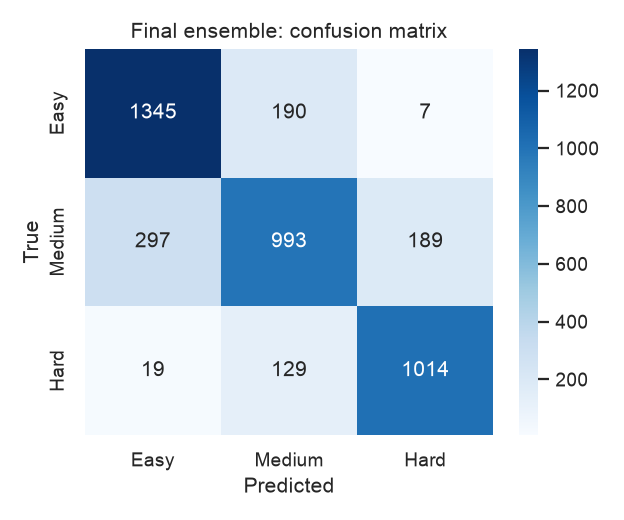

In [5]:
print('Ensemble configuration:', json.loads((ROOT/'models_store/ensemble.json').read_text()))
show('confusion_matrix_ensemble.png')

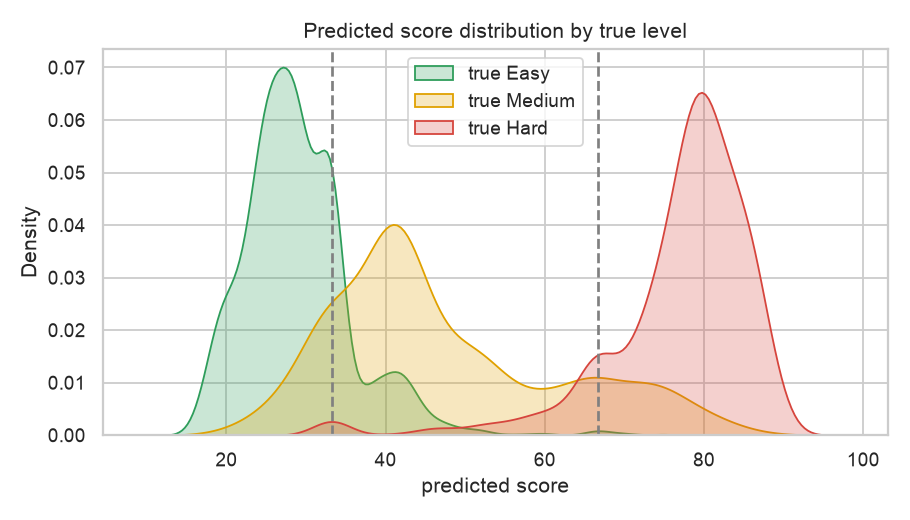

In [6]:
show('score_distribution.png')

## Per-source analysis: does the score follow the educational level?

In [7]:
ps = pd.read_csv(REPORTS/'per_source_results.csv'); ps

,group,n,target_score,mean_pred_score,level_accuracy
0,arith_basic,130.0,12.0,16.740,1.000
1,sciq,300.0,18.0,22.554,0.977
2,prealgebra_basic,148.0,24.0,21.792,1.000
3,commonsense_qa,300.0,25.0,26.031,0.957
4,arc_easy,300.0,28.0,34.487,0.710
5,race_middle,300.0,28.0,30.955,0.750
6,gsm8k,300.0,30.0,30.390,0.977
7,mmlu_elementary,42.0,30.0,33.543,0.810
8,openbookqa,300.0,40.0,38.866,0.847
9,race_high,300.0,42.0,38.514,0.737


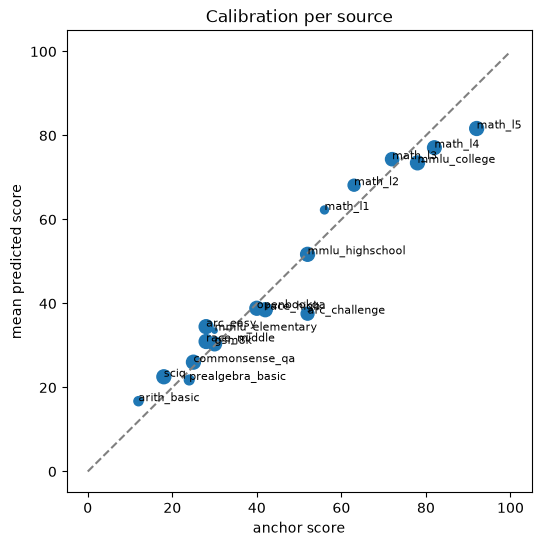

In [8]:
plt.figure(figsize=(6,6)); plt.scatter(ps.target_score, ps.mean_pred_score, s=ps.n/3)
for _,r in ps.iterrows(): plt.annotate(r.group, (r.target_score, r.mean_pred_score), fontsize=8)
plt.plot([0,100],[0,100],'--',c='grey'); plt.xlabel('anchor score'); plt.ylabel('mean predicted score'); plt.title('Calibration per source'); plt.show()

## Explainability

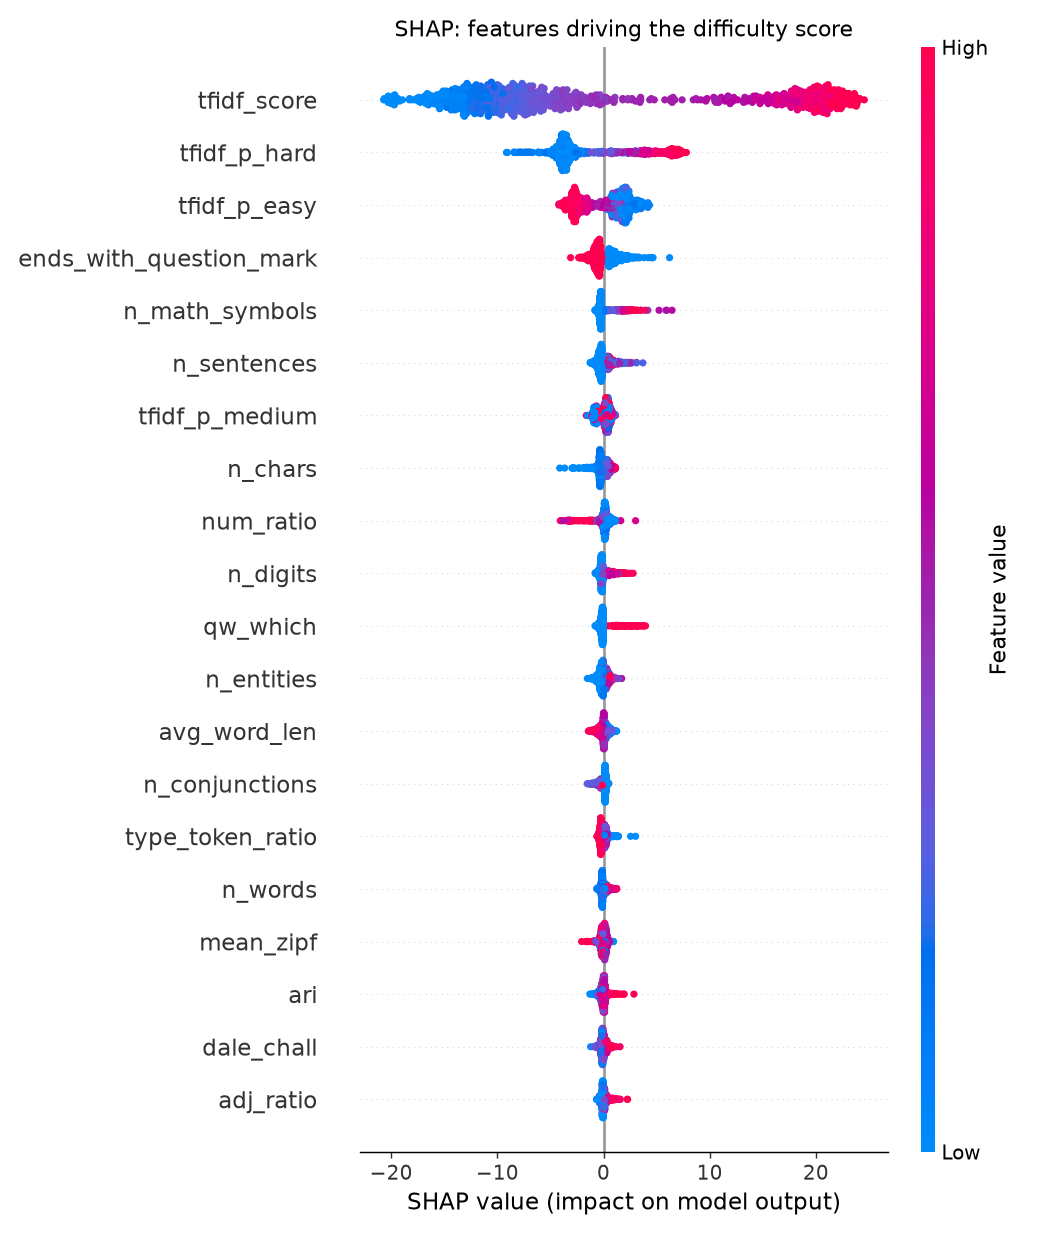

In [9]:
show('shap_summary.png')

In [10]:
pd.read_csv(REPORTS/'shap_mean_abs.csv').head(15)

,Unnamed: 0,mean_abs_shap
0,tfidf_score,12.276145
1,tfidf_p_hard,3.934899
2,tfidf_p_easy,2.029342
3,ends_with_question_mark,0.911532
4,n_math_symbols,0.618119
5,n_sentences,0.520254
6,tfidf_p_medium,0.441859
7,n_chars,0.405535
8,num_ratio,0.383735
9,n_digits,0.354184


## Error analysis

In [11]:
tp = pd.read_csv(REPORTS/'test_predictions.csv')
from src.config import LEVELS
tp['pred_level'] = tp.pred_label.map(dict(enumerate(LEVELS)))
err = tp[tp.level != tp.pred_level]
print(f'{len(err)} errors of {len(tp)}'); display(pd.crosstab(err.group, err.pred_level))
err.sample(12, random_state=0)[['group','question','level','pred_level','pred_score']]

831 errors of 4461


pred_level,Easy,Hard,Medium
group,,,
arc_challenge,127,0,0
arc_easy,0,0,87
commonsense_qa,0,0,13
gsm8k,0,4,3
math_l1,7,28,0
math_l2,15,130,0
math_l3,5,0,50
math_l4,7,0,30
math_l5,2,0,11


,group,question,level,pred_level,pred_score
1592,race_high,In the hospital _ .,Medium,Easy,29.543421
2472,math_l1,"Given the two functions f(x)=x^2+1 and g(x)=2x-1 , find f(g(5)) .",Medium,Hard,72.964117
944,openbookqa,In what way are valleys formed?,Medium,Easy,23.174303
2012,race_middle,The example of the company Google is given to show that _ .,Easy,Medium,44.226769
16,arc_challenge,Magnesium bromide is one of the most abundant compounds found in sea water. Which formula correctly represents magne...,Medium,Easy,33.300000
3218,math_l2,"The digits of a two-digit number AB are reversed to form a second two-digit number, and the lesser of the two-digit ...",Medium,Hard,77.612324
3169,math_l2,What is the smallest four-digit positive integer that is divisible by 47?,Medium,Hard,70.863083
3331,math_l2,The sum of four numbers is one-half. What is the mean of the four numbers? Express your answer as a common fraction.,Medium,Hard,72.829235
3284,math_l5,The sum of two numbers is 15. Four times the smaller number is 60 less than twice the larger number. What is the lar...,Hard,Medium,66.140255
3564,mmlu_college,Chemosynthetic bacteria can produce their own food despite their lack of photonabsorbing pigments because the chemos...,Hard,Medium,45.481093


## Using the predictor

In [12]:
from src.predict import get_predictor
p = get_predictor()
tests = ['What is the capital of France?', 'Explain why the sky appears blue during the day.',
         'A car accelerates uniformly from 10 m/s to 30 m/s in 5 seconds. Calculate its acceleration.',
         'Evaluate the impact of the Treaty of Versailles on the rise of fascism in Europe.',
         'Find all positive integers n such that n^2 + 1 is divisible by n + 1.']
p.predict_batch(tests)[['question','level','score','confidence','p_easy','p_medium','p_hard']]

W1117 03:17:11.151000 77626 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

,question,level,score,confidence,p_easy,p_medium,p_hard
0,What is the capital of France?,Easy,25.6,0.933,0.933,0.052,0.016
1,Explain why the sky appears blue during the day.,Easy,33.3,0.579,0.579,0.413,0.008
2,A car accelerates uniformly from 10 m/s to 30 m/s in 5 seconds. Calculate its acceleration.,Medium,50.5,0.816,0.101,0.816,0.083
3,Evaluate the impact of the Treaty of Versailles on the rise of fascism in Europe.,Medium,54.6,0.865,0.017,0.865,0.118
4,Find all positive integers n such that n^2 + 1 is divisible by n + 1.,Hard,79.9,0.907,0.009,0.084,0.907


In [13]:
r = p.predict('Prove that there are infinitely many prime numbers.')
print(r['level'], r['score'], r['probabilities']); print('SHAP:', r['shap'][:5]); print('Attention:', r.get('attention'))

Hard 71.7 {'Easy': 0.037, 'Medium': 0.384, 'Hard': 0.579}
SHAP: [('tfidf_score', 16.87, 62.457), ('tfidf_p_hard', 3.7, 0.658), ('tfidf_p_easy', 2.34, 0.018), ('ends_with_question_mark', 1.55, 0.0), ('n_chars', -1.07, 51.0)]
Attention: [('prove', 0.11599999666213989), ('that', 0.024000000208616257), ('there', 0.00800000037997961), ('are', 0.004999999888241291), ('infinitely', 0.16599999368190765), ('many', 0.07000000029802322), ('prime', 0.3779999911785126), ('numbers', 0.23399999737739563)]
